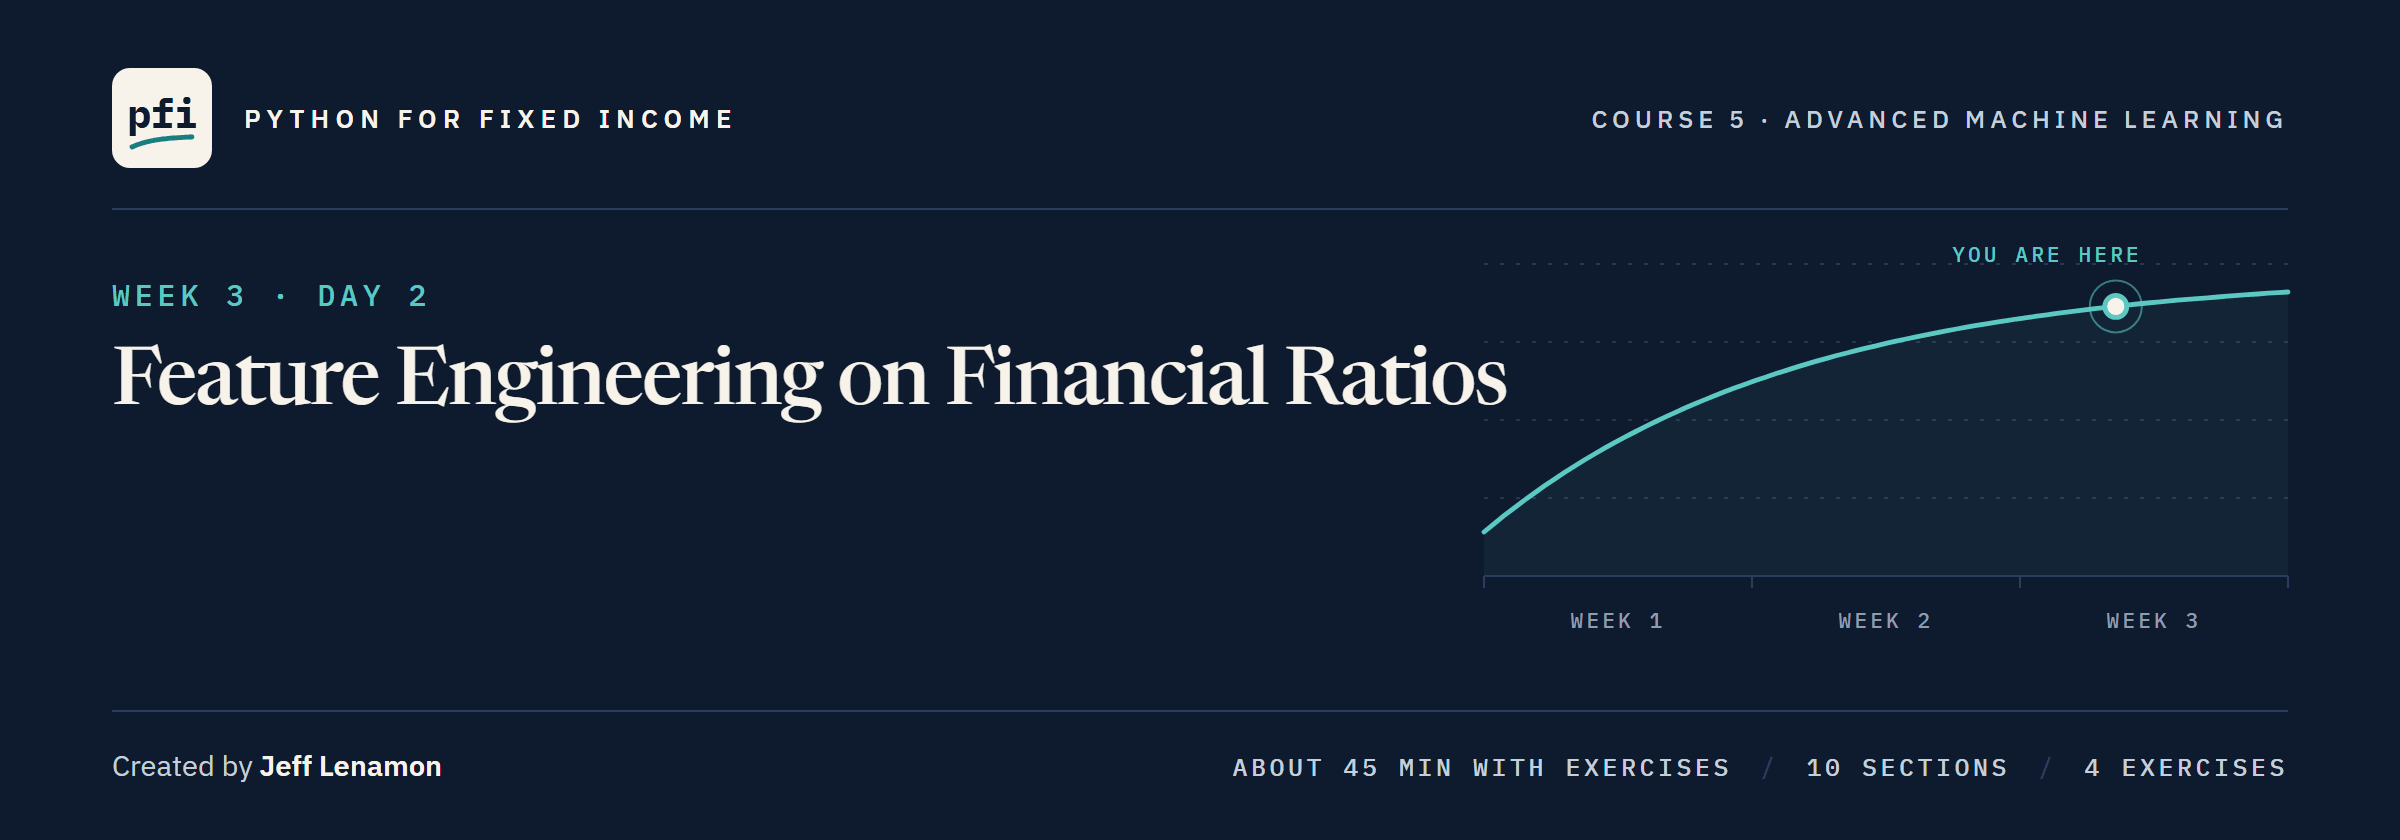

# Feature Engineering on Financial Ratios

Week 3, Day 2. Write a shape or a fact into a column, score what it adds against the noise of the folds, and learn every number a column needs inside the fold.

**Data:** `benchmark.csv` and `ratings.csv`, 821 bonds of invented issuers: **synthetic**, made for this course by `tools/make_holdings.py`. No real issuer, price, or spread.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day2/12_feature_engineering_on_financial_ratios.ipynb)

# Problem Statement

## Business Context

Day 11 left two models on the Polish training rows: LightGBM at its defaults, at a fold average precision of 0.7783, and Course 4's logistic pipeline, at 0.6624.
The colleague who brought the file asks what every analyst asks next: we build ratios by hand, so can better columns lift either model?
**Feature engineering** is building new columns from the ones a file already has: a cap, a ratio, a count, a transform, a share.
A warm-up comes first, on the course's synthetic bonds, where the answer is known because the generator's recipe is.
Then the Polish companies, where nobody hands us a recipe.
A fitted spread here describes synthetic bonds, and a model's output on the Polish file is the model's probability of bankruptcy in this file: neither is a credit view on any bond or company.

## Objectives

Write a known shape into a column and score it on folds, build a ratio from two ratios and guard its division, and turn gaps into columns.
Transform a long-tailed ratio for a linear model, learn a column's numbers inside each fold, encode a group's bankrupt share inside the folds, and weigh what each new column adds against the fold noise.

## Data Dictionary

`benchmark.csv` and `ratings.csv`, the course's 821 synthetic bonds of invented issuers, in the first section only:

1. `rating` and its `score`, 1 for AAA up to 18 for CCC
2. `maturity` and `as_of_date`, which give years to maturity
3. `oas`: option-adjusted spread, bp; **the target is its log**

`polish_bankruptcy_5year.csv`, one row per financial statement, from then on:

1. `Attr1` to `Attr64`: the page's X1 to X64, ratios from the statements
2. `class`: 1 if the company went bankrupt within a year, **the target**

The ratios this notebook names, as the page defines them:

- `Attr2`: total liabilities / total assets
- `Attr7`: EBIT / total assets
- `Attr8`: book value of equity / total liabilities
- `Attr10`: equity / total assets
- `Attr27`: profit on operating activities / financial expenses
- `Attr37`: (current assets - inventories) / long-term liabilities
- `Attr51`: short-term liabilities / total assets

## Your Route Through Day 2

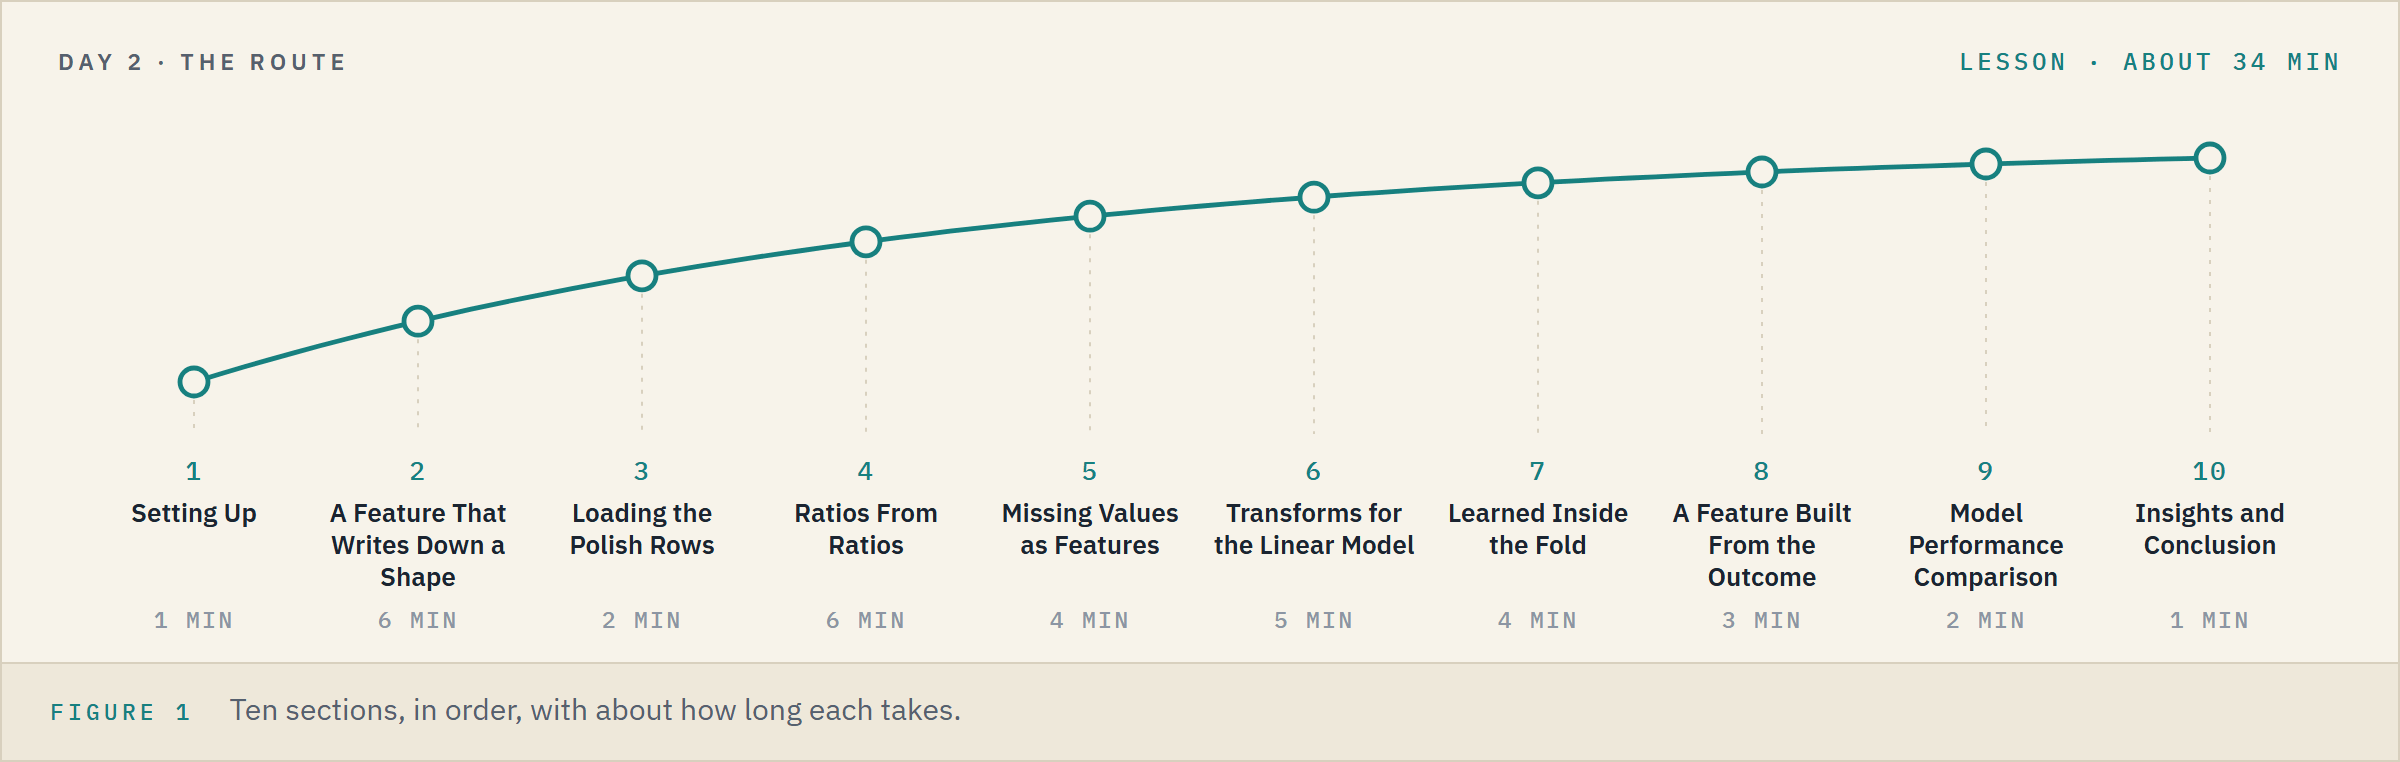

**Time.** About 34 minutes for the lesson, then about 12 for the four exercises.

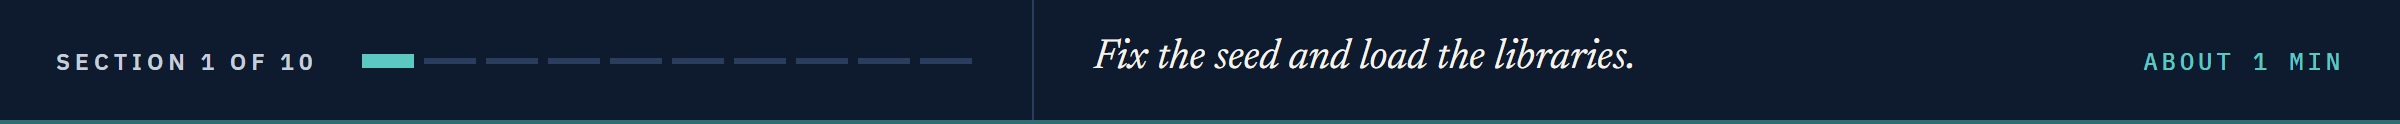

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split and fold the rows, and score on the folds
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate

# pipeline steps: Course 4's, and two new ones
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer, FunctionTransformer, TargetEncoder

# the models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor
from lightgbm import LGBMClassifier

# to measure misses in bp, and to score a fold by hand
from sklearn.metrics import mean_absolute_error, make_scorer, average_precision_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

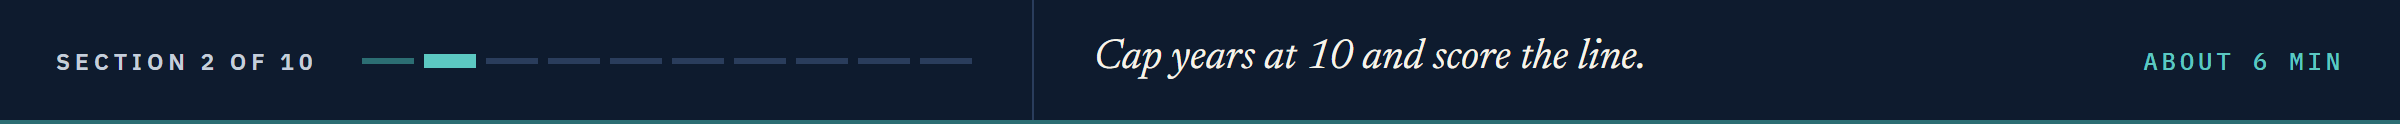

# A Feature That Writes Down a Shape

## The Bonds and Course 4's Split

In [3]:
# the 821 bonds with their rating scores, years to maturity, and the target: the log of OAS, as on Day 7
bonds = pd.read_csv(DATA + "benchmark.csv").merge(pd.read_csv(DATA + "ratings.csv")[["rating", "score"]], on="rating")
bonds["years_to_maturity"] = (pd.to_datetime(bonds["maturity"]) - pd.to_datetime(bonds["as_of_date"])).dt.days / 365.25
bonds["log_oas"] = np.log(bonds["oas"])

# Course 4's split: the same 615 training bonds; the test bonds are never scored in Course 5
train, test = train_test_split(bonds, test_size=0.25, random_state=SEED)
print("Training bonds:", len(train), " Past 10 years:", (train["years_to_maturity"] > 10).sum())

Training bonds: 615  Past 10 years: 181


Day 7 read the generator's maturity factor, `0.70 + 0.30 * min(years, 10) / 10`: it rises to 10 years, then stays flat.

181 of the 615 training bonds sit on the flat part.

## Years as They Are

In [4]:
# Day 7's five folds of the training bonds, and its miss in bp, both logs turned back through exp first
bond_folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
def mae_bp(y_log, fitted_log):
    return mean_absolute_error(np.exp(y_log), np.exp(fitted_log))
bp_scorer = make_scorer(mae_bp, greater_is_better=False)

# the MAE in bp on each held-out fold of one model on some columns
def fold_bp(model, columns):
    return -cross_val_score(model, train[columns], train["log_oas"], cv=bond_folds, scoring=bp_scorer, n_jobs=1)

In [5]:
# least squares and Day 7's boosting on score and years as they are
bond_mae = pd.DataFrame({"line, years": fold_bp(LinearRegression(), ["score", "years_to_maturity"]),
                         "boosting, years": fold_bp(GradientBoostingRegressor(random_state=SEED), ["score", "years_to_maturity"])},
                        index=range(1, 6))
bond_mae.mean()

line, years       42.3147
boosting, years   41.2423
dtype: float64

Day 7's two numbers: the line misses by 42.31 bp, boosting by 41.24.

Boosting finds the bend at 10 years with its splits; one straight slope in years cannot bend.

**Predict 1**

Q. Give the line years capped at 10 in place of years, and nothing else. Write down its fold MAE in bp, against 42.31 for the line and 41.24 for boosting.

## Years Capped at 10

A **cap** is Course 1's `.clip(upper=10)`: every value past 10 becomes 10.
The log of years is a second guess at the bend, for comparison.

In [6]:
# the recipe's shape written into a column, and a log as another guess at a bend
train["years_capped"] = train["years_to_maturity"].clip(upper=10)
train["log_years"] = np.log(train["years_to_maturity"])

# the line on each, on the same folds
bond_mae["line, log years"] = fold_bp(LinearRegression(), ["score", "log_years"])
bond_mae["line, capped"] = fold_bp(LinearRegression(), ["score", "years_capped"])
bond_mae.T.assign(mean=bond_mae.mean())

,1,2,3,4,5,mean
"line, years",30.8995,37.2303,63.3381,36.0074,44.0983,42.3147
"boosting, years",28.3476,40.6032,62.9205,34.8821,39.4579,41.2423
"line, log years",30.4072,36.3312,62.0526,35.1960,42.6356,41.3245
"line, capped",30.3551,36.4202,61.9384,34.5653,41.0918,40.8741


The capped line misses by 40.87 bp: 1.44 bp better than years as they are, 0.37 below boosting at its defaults, and 0.36 above Day 7's stumps (40.51).

It beats boosting on 3 of 5 folds; the log of years, which bends everywhere and never flattens, lands at 41.32.

In [7]:
# the three models fitted on all 615 training bonds
line = LinearRegression().fit(train[["score", "years_to_maturity"]], train["log_oas"])
capped = LinearRegression().fit(train[["score", "years_capped"]], train["log_oas"])
boosting = GradientBoostingRegressor(random_state=SEED).fit(train[["score", "years_to_maturity"]], train["log_oas"])

# each one's fitted spread in bp along years, at score 9 (BBB)
along = pd.DataFrame({"score": 9, "years_to_maturity": np.arange(0.5, 30.01, 0.5)})
along["years_capped"] = along["years_to_maturity"].clip(upper=10)
curves = pd.DataFrame({"line, years": np.exp(line.predict(along[["score", "years_to_maturity"]])),
                       "line, capped": np.exp(capped.predict(along[["score", "years_capped"]])),
                       "boosting, years": np.exp(boosting.predict(along[["score", "years_to_maturity"]]))},
                      index=along["years_to_maturity"])
curves.loc[[1.0, 10.0, 30.0]]

,"line, years","line, capped","boosting, years"
years_to_maturity,,,
1.0000,116.8504,106.9025,82.8202
10.0000,127.4120,138.1144,131.4466
30.0000,154.4263,138.1144,104.1055


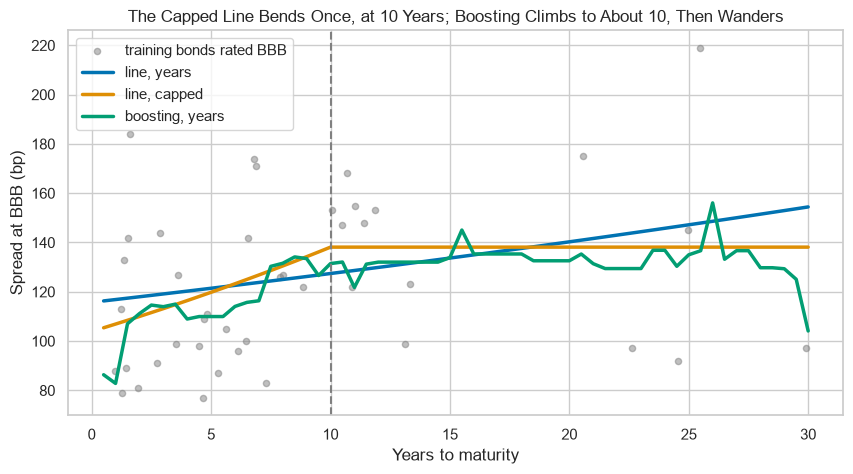

In [8]:
# the BBB training bonds as dots, the three fitted curves, the recipe's 10 years dashed
bbb = train[train["score"] == 9]
plt.scatter(bbb["years_to_maturity"], bbb["oas"], s=20, color="gray", alpha=0.5, label="training bonds rated BBB")
for name in curves:
    plt.plot(curves.index, curves[name], linewidth=2.5, label=name)
plt.axvline(10, color="gray", linestyle="--")
plt.xlabel("Years to maturity")
plt.ylabel("Spread at BBB (bp)")
plt.title("The Capped Line Bends Once, at 10 Years; Boosting Climbs to About 10, Then Wanders")
plt.legend(loc="upper left")
plt.show()

The capped line rises from 106.9 bp at 1 year to 138.1 at 10, then stays flat, as the recipe does.

The plain line keeps climbing, to 154.4 at 30 years; boosting falls from 131.4 at 10 years to 104.1 at 30, a dip the recipe does not have.

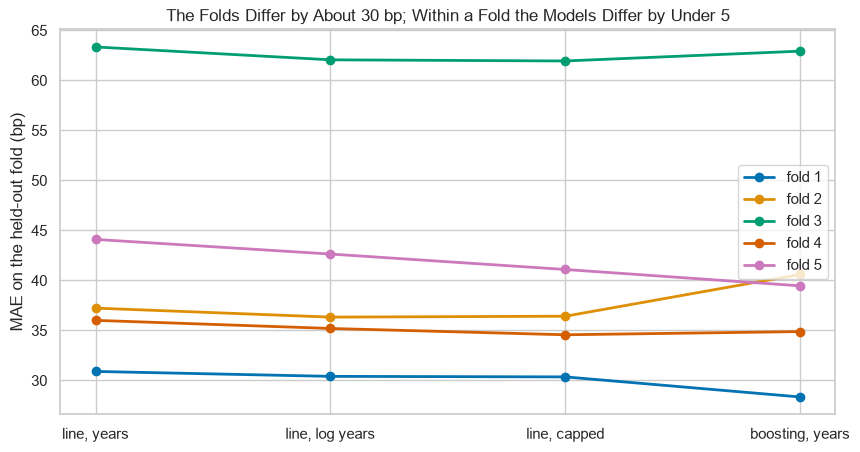

In [9]:
# one line per fold across the four models
order = ["line, years", "line, log years", "line, capped", "boosting, years"]
for fold, row in bond_mae[order].iterrows():
    plt.plot(order, row.values, marker="o", linewidth=2, label="fold " + str(fold))
plt.ylabel("MAE on the held-out fold (bp)")
plt.title("The Folds Differ by About 30 bp; Within a Fold the Models Differ by Under 5")
plt.legend(loc="center right")
plt.show()

Fold 3 is the hardest for every model, near 62 bp, and fold 1 the easiest, near 30.

Within a fold the models differ by under 5 bp, and the capped line and boosting swap places from fold to fold, so the folds cannot rank them.

**One column holding the recipe's shape brings a plain least squares line level with boosting, which had to find the bend itself. From here on the notebook works on the Polish file, which comes with no recipe: every new column is a guess, scored on folds.**

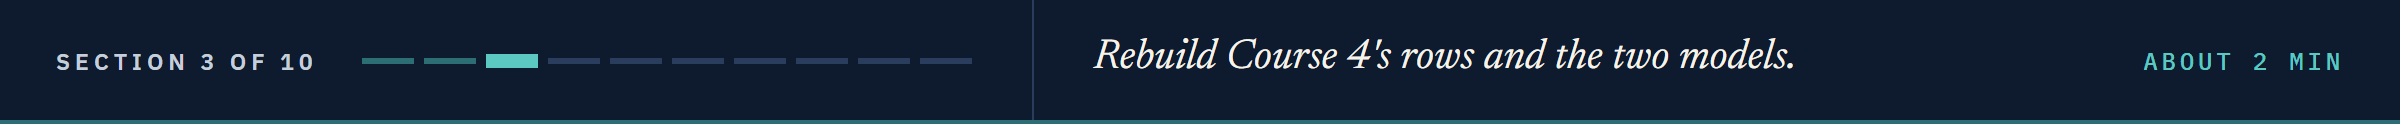

# Loading the Polish Rows

## Course 4's Rows, Day 11's Folds

In [10]:
# Course 4's capstone rows: the exact copies out, then one stratified 80/20 split with the course seed
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]
unique = bankrupt.drop_duplicates()
X_train, X_test, y_train, y_test = train_test_split(unique[FEATURES], unique[TARGET], test_size=0.2, stratify=unique[TARGET],
                                                    random_state=SEED)
print(len(bankrupt), "read,", len(unique), "unique.  Training:", len(X_train), "rows,", y_train.sum(), "bankrupt,",
      round(y_train.mean() * 100, 2), "percent")

5910 read, 5850 unique.  Training: 4680 rows, 326 bankrupt, 6.97 percent


In [11]:
# Day 11's five stratified folds, and the fold average precision of a model on the training rows
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def fold_ap(model):
    return cross_val_score(model, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)

The same 4,680 training rows as Course 4's capstone and Day 11; the 1,170 test rows are never scored in Course 5.

## The Two Models to Beat

In [12]:
# Course 4's logistic pipeline, and Day 11's LightGBM at its defaults
logistic = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])
booster = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)

# every model's fold scores, one column each, kept in one table
scores = pd.DataFrame({"LightGBM": fold_ap(booster), "logistic": fold_ap(logistic)}, index=range(1, 6))

In [13]:
# some models' fold scores, their mean, and their fold sd (ddof=0, as Day 11's)
def summary(names):
    table = scores[names].T
    return table.assign(mean=table.mean(axis=1), sd=table.std(axis=1, ddof=0))

summary(["LightGBM", "logistic"])

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
logistic,0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780


**Every new column today is scored against these two means, on these five folds, beside fold sds of 0.0469 and 0.0780.**

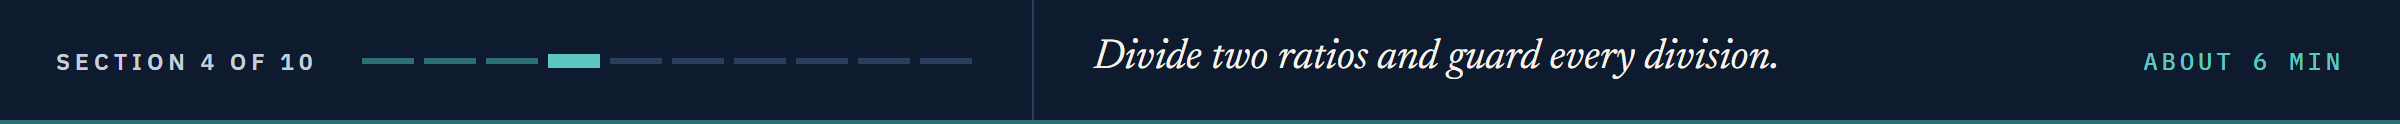

# Ratios From Ratios

## Dividing Two Ratios

Many of the 64 ratios have total assets underneath, so dividing one of them by another cancels it:

- `Attr7 / Attr2` is EBIT / total liabilities
- `Attr51 / Attr2` is the short-term share of liabilities
- `Attr2 / Attr10` is total liabilities / equity, **debt to equity**

In [14]:
# denominators at exactly zero, and what plain division makes of them
print("Attr2 at 0:", (X_train["Attr2"] == 0).sum(), " Attr10 at 0:", (X_train["Attr10"] == 0).sum())
plain = X_train["Attr7"] / X_train["Attr2"]
print("EBIT to liabilities, infinite:", np.isinf(plain).sum(), " Missing:", plain.isna().sum())

Attr2 at 0: 12  Attr10 at 0: 1
EBIT to liabilities, infinite: 9  Missing: 5


In [15]:
# the guard: .replace() turns each infinity into a gap
guarded = plain.replace([np.inf, -np.inf], np.nan)
print("Infinite:", np.isinf(guarded).sum(), " Missing:", guarded.isna().sum())

Infinite: 0  Missing: 14


12 companies report no liabilities at all, and plain division gives 9 of them an infinite ratio, which no model can use.

The guard turns those 9 into gaps, 14 gaps in all with the 5 already there: LightGBM handles gaps (Day 11), and the logistic pipeline's imputer fills them.

## Liabilities and Equity Fill the Balance Sheet

In [16]:
# liabilities plus equity, each over total assets: how often do they make 1?
total = X_train["Attr2"] + X_train["Attr10"]
print("Within 0.01 of 1:", ((total - 1).abs() < 0.01).sum(), "of", total.notna().sum(), " Median:", round(total.median(), 4))
print("Companies with equity below 0:", (X_train["Attr10"] < 0).sum())

Within 0.01 of 1: 3389 of 4678  Median: 1.0
Companies with equity below 0: 268


On 3,389 of 4,678 companies liabilities and equity make 1 within 0.01, so for most companies equity is close to 1 minus `Attr2`.

268 companies have equity below 0.

**Predict 2**

Q. Sketch debt to equity, `Attr2 / Attr10`, against `Attr2` from 0 to 2. How does it move as `Attr2` nears 1, and past it?

## Where a Ratio Breaks

In [17]:
# debt to equity for every training company, guarded, and the curve the balance sheet gives it
debt_to_equity = (X_train["Attr2"] / X_train["Attr10"]).replace([np.inf, -np.inf], np.nan)
went = y_train == 1
below, above = np.linspace(0, 0.99, 200), np.linspace(1.01, 2, 200)

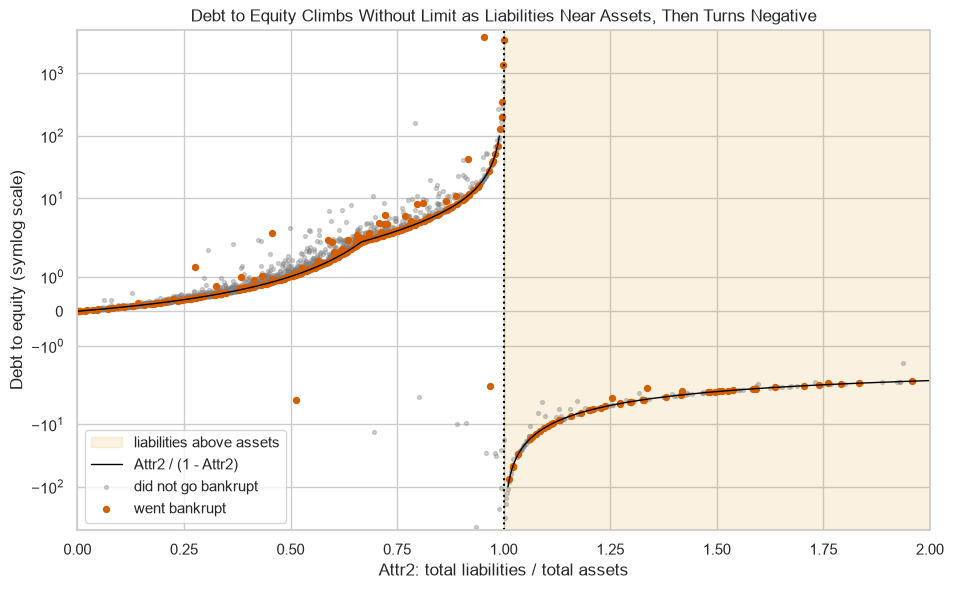

In [18]:
# the companies on a symlog axis (Course 4's Day 10), the bankrupt ones dark, Attr2 above 1 shaded
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axvspan(1, 2, color="C1", alpha=0.12, label="liabilities above assets")
ax.plot(below, below / (1 - below), color="black", linewidth=1, label="Attr2 / (1 - Attr2)")
ax.plot(above, above / (1 - above), color="black", linewidth=1)
ax.scatter(X_train.loc[~went, "Attr2"], debt_to_equity[~went], s=8, color="gray", alpha=0.35, label="did not go bankrupt")
ax.scatter(X_train.loc[went, "Attr2"], debt_to_equity[went], s=18, color="C3", label="went bankrupt")
ax.axvline(1, color="black", linestyle=":")
ax.set(yscale="symlog", xlim=(0, 2), ylim=(-500, 5000), xlabel="Attr2: total liabilities / total assets",
       ylabel="Debt to equity (symlog scale)")
ax.set_title("Debt to Equity Climbs Without Limit as Liabilities Near Assets, Then Turns Negative")
ax.legend(loc="lower left")
plt.show()

In [19]:
# the bankrupt share where debt to equity is below 0, and among the rest; the companies off the chart's edges
negative = debt_to_equity < 0
print("Below 0:", negative.sum(), "companies,", round(y_train[negative].mean() * 100, 1), "percent bankrupt")
print("The rest:", round(y_train[~negative].mean() * 100, 1), "percent bankrupt")
print("Attr2 above 2 or below 0, off the chart:", ((X_train["Attr2"] > 2) | (X_train["Attr2"] < 0)).sum())

Below 0: 269 companies, 29.0 percent bankrupt
The rest: 5.6 percent bankrupt
Attr2 above 2 or below 0, off the chart: 53


Below 1 most companies ride the curve `Attr2 / (1 - Attr2)`, and the ratio climbs without limit as liabilities near assets: an asymptote at 1.

Past 1 equity is negative and the ratio flips below 0: 269 companies sit below 0, 29.0 percent bankrupt against 5.6 percent among the rest.

So the weakest balance sheets get the lowest debt to equity of all, while `Attr2` keeps the same companies in order with no break.

53 companies with `Attr2` above 2 or below 0 sit off the chart's edges.

### The File Has It Already

In [20]:
# the page's X8 is book equity / total liabilities: is debt to equity just 1 / Attr8?
both = pd.DataFrame({"ours": debt_to_equity, "the file's": 1 / X_train["Attr8"]}).replace([np.inf, -np.inf], np.nan).dropna()
print(np.isclose(both["ours"], both["the file's"], rtol=0.01).sum(), "of", len(both), "agree within 1 percent")

4666 of 4666 agree within 1 percent


Every company agrees: debt to equity is 1 / `Attr8`, so a model had the same fact all along, written another way.

## A Step That Learns Nothing

`FunctionTransformer(func)` wraps a function as a pipeline step: its `fit` learns nothing, and its `transform` calls the function.

In [21]:
# the three ratios as new columns, every division guarded
def add_ratios(frame):
    ratios = pd.DataFrame({"debt_to_equity": frame["Attr2"] / frame["Attr10"],
                           "ebit_to_liabilities": frame["Attr7"] / frame["Attr2"],
                           "short_term_share": frame["Attr51"] / frame["Attr2"]})
    return pd.concat([frame, ratios.replace([np.inf, -np.inf], np.nan)], axis=1)

ratio_step = FunctionTransformer(add_ratios)
print(ratio_step.fit_transform(X_train).shape)

(4680, 67)


Each row's ratios come from that row alone, so the step can sit anywhere in a pipeline.

**A ratio makes a good column only where its denominator stays away from zero; the folds score these three later.**

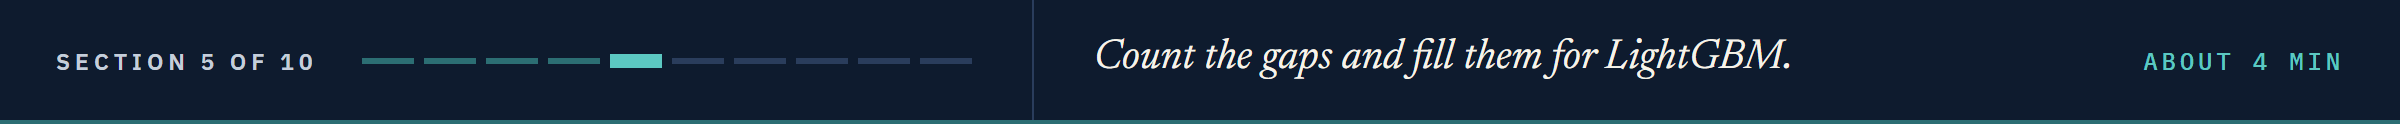

# Missing Values as Features

## Gaps by Company

In [22]:
# gaps on each company's row, and the bankrupt share by gap count, 3 or more as one group
gaps = X_train.isna().sum(axis=1)
print("Companies with a gap:", (gaps > 0).sum(), " Most on one row:", gaps.max())
by_gaps = y_train.groupby(gaps.clip(upper=3)).agg(["size", "mean"])
by_gaps["mean"] = by_gaps["mean"] * 100
by_gaps

Companies with a gap: 2248  Most on one row: 32


,size,mean
0,2432,3.5773
1,1698,7.5383
2,272,26.1029
3,278,14.3885


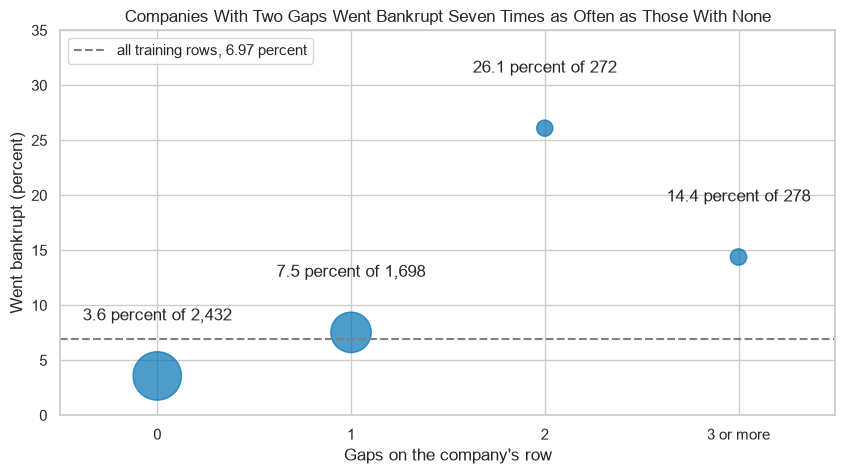

In [23]:
# each group's bankrupt share as a dot sized by its companies, the overall share dashed
labels = ["0", "1", "2", "3 or more"]
plt.scatter(labels, by_gaps["mean"], s=by_gaps["size"] / 2, alpha=0.7)
for label, share, size in zip(labels, by_gaps["mean"], by_gaps["size"]):
    plt.annotate(f"{share:.1f} percent of {size:,}", (label, share), textcoords="offset points", xytext=(0, 40), ha="center")
plt.axhline(y_train.mean() * 100, color="gray", linestyle="--", label="all training rows, 6.97 percent")
plt.ylim(0, 35)
plt.xlim(-0.5, 3.5)
plt.xlabel("Gaps on the company's row")
plt.ylabel("Went bankrupt (percent)")
plt.title("Companies With Two Gaps Went Bankrupt Seven Times as Often as Those With None")
plt.legend(loc="upper left")
plt.show()

2,248 of the 4,680 companies have a gap, and one has 32.

With no gap 3.6 percent went bankrupt; with two, 26.1 percent.

Course 4's capstone measured the logistic pipeline's missing indicators: without them its 0.6624 fell to 0.4477.

**Predict 3**

Q. Day 11 gave LightGBM the gaps as they are. Put a median imputer, without Course 4's missing indicators, in front of it. Write down the fold average precision, against 0.7783.

## Filling the Gaps for LightGBM

In [24]:
# a median imputer, without Course 4's missing indicators, in front of the same booster
scores["LightGBM, median fill"] = fold_ap(Pipeline([("impute", SimpleImputer(strategy="median")), ("lightgbm", booster)]))
summary(["LightGBM", "LightGBM, median fill"])

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
"LightGBM, median fill",0.7184,0.7628,0.7304,0.7684,0.8004,0.7561,0.0291


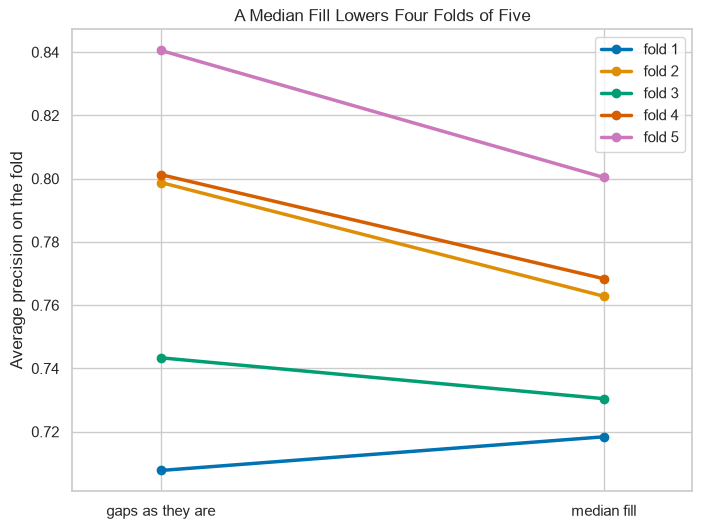

In [25]:
# one line per fold: the gaps as they are on the left, filled with medians on the right
plt.figure(figsize=(8, 6))
for fold, row in scores[["LightGBM", "LightGBM, median fill"]].iterrows():
    plt.plot([0, 1], row.values, marker="o", linewidth=2.5, label="fold " + str(fold))
plt.xticks([0, 1], ["gaps as they are", "median fill"])
plt.xlim(-0.2, 1.2)
plt.ylabel("Average precision on the fold")
plt.title("A Median Fill Lowers Four Folds of Five")
plt.legend(loc="upper right")
plt.show()

The median fill scores 0.7561, 0.022 below the gaps as they are, and lower on 4 of 5 folds.

A median puts a missing ratio among the ordinary companies, where LightGBM can no longer tell a gap from a middling value.

## A Gap Count

In [26]:
# the count of gaps as one more column, a step that learns nothing, in front of each model
def add_gap_count(frame):
    return frame.assign(gap_count=frame.isna().sum(axis=1))

scores["LightGBM, gap count"] = fold_ap(Pipeline([("gaps", FunctionTransformer(add_gap_count)), ("lightgbm", booster)]))
scores["logistic, gap count"] = fold_ap(Pipeline([("gaps", FunctionTransformer(add_gap_count)), ("logistic", logistic)]))
summary(["LightGBM", "LightGBM, gap count", "logistic", "logistic, gap count"])

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
"LightGBM, gap count",0.6958,0.7985,0.7350,0.8026,0.8258,0.7715,0.0484
logistic,0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780
"logistic, gap count",0.5418,0.7227,0.6194,0.6788,0.7541,0.6634,0.0758


A pipeline can be a step of another pipeline, as `logistic` is here.

The count moves LightGBM to 0.7715 and the logistic pipeline to 0.6634, each far inside its fold sd.

**LightGBM reads a gap better than a median does, and a count of gaps tells neither model anything new.**

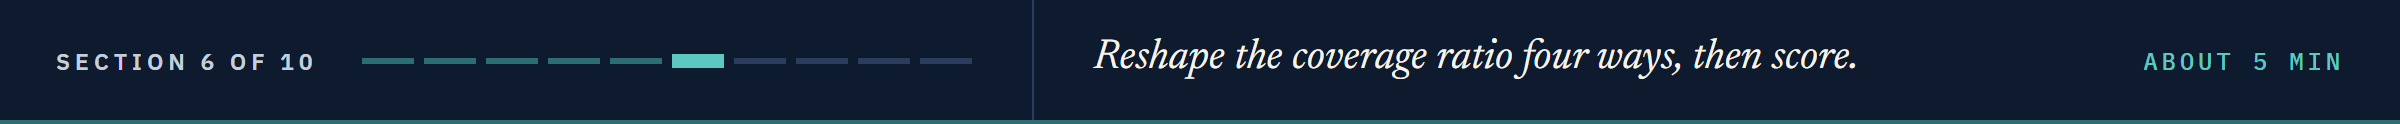

# Transforms for the Linear Model

## A Coverage Ratio With Long Tails

In [27]:
# Attr27, operating profit over financial expenses: gaps, range, skew, and the median by outcome
coverage = X_train["Attr27"]
print("Gaps:", coverage.isna().sum(), " Min:", coverage.min(), " Median:", round(coverage.median(), 2), " Max:", coverage.max(),
      " Skew:", round(coverage.skew(), 1))
print("Median, went bankrupt:", round(coverage[went].median(), 2), " did not:", round(coverage[~went].median(), 2))

Gaps: 317  Min: -158130.0  Median: 0.99  Max: 214880.0  Skew: 15.5
Median, went bankrupt: -1.29  did not: 1.02


The median company sits at 0.99, and the tails reach past 150,000 on each side.

The two outcomes part in the middle, -1.29 against 1.02, a hair either side of zero.

## Four Ways to Feed It to a Line

- **standardized**: Course 4's `StandardScaler`
- **clipped**: `.clip(low, high)` at the 1st and 99th percentiles, Course 1's clip with two bounds
- **arcsinh**: `np.arcsinh`, close to the value near zero and to a signed log far out, so it keeps the sign and learns nothing
- **quantile**: Course 4's normal scores

In [28]:
# a demonstration, fitted on all the training rows with a value: Attr27 four ways
# .to_frame() makes the column a one-column table, the shape a scikit-learn step takes
rows = coverage.dropna()
all_low, all_high = rows.quantile(0.01), rows.quantile(0.99)
versions = pd.DataFrame({"standardized": StandardScaler().fit_transform(rows.to_frame())[:, 0],
                         "clipped": rows.clip(all_low, all_high),
                         "arcsinh": np.arcsinh(rows),
                         "quantile": QuantileTransformer(output_distribution="normal", random_state=SEED).fit_transform(rows.to_frame())[:, 0]},
                        index=rows.index)
print("Standardized within 0.1 of zero:", round((versions["standardized"].abs() < 0.1).mean() * 100, 2), "percent  Largest:",
      round(versions["standardized"].abs().max(), 1), "sd")
print("Clip bounds:", round(all_low, 2), "and", round(all_high, 2))

Standardized within 0.1 of zero: 97.69 percent  Largest: 29.5 sd
Clip bounds: -77.66 and 4516.71


### Your Turn: Pick a Version

In [29]:
# one version as two histograms, the bankrupt companies and the rest, each scaled to an area of 1
outcome = y_train[rows.index].map({0: "did not go bankrupt", 1: "went bankrupt"}).rename("company")
def draw_version(version, ax, legend=True):
    sns.histplot(x=versions[version], hue=outcome, stat="density", common_norm=False, bins=60, element="step", ax=ax,
                 legend=legend)
    # .capitalize() starts the panel's title with a capital letter
    ax.set(xlabel="Attr27, " + version, title=version.capitalize())

In [30]:
# your turn: pick a version and watch where the companies sit
def show_version(version="standardized"):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    draw_version(version, ax)
    plt.show()

interact(show_version, version=list(versions.columns));

interactive(children=(Dropdown(description='version', options=('standardized', 'clipped', 'arcsinh', 'quantile…

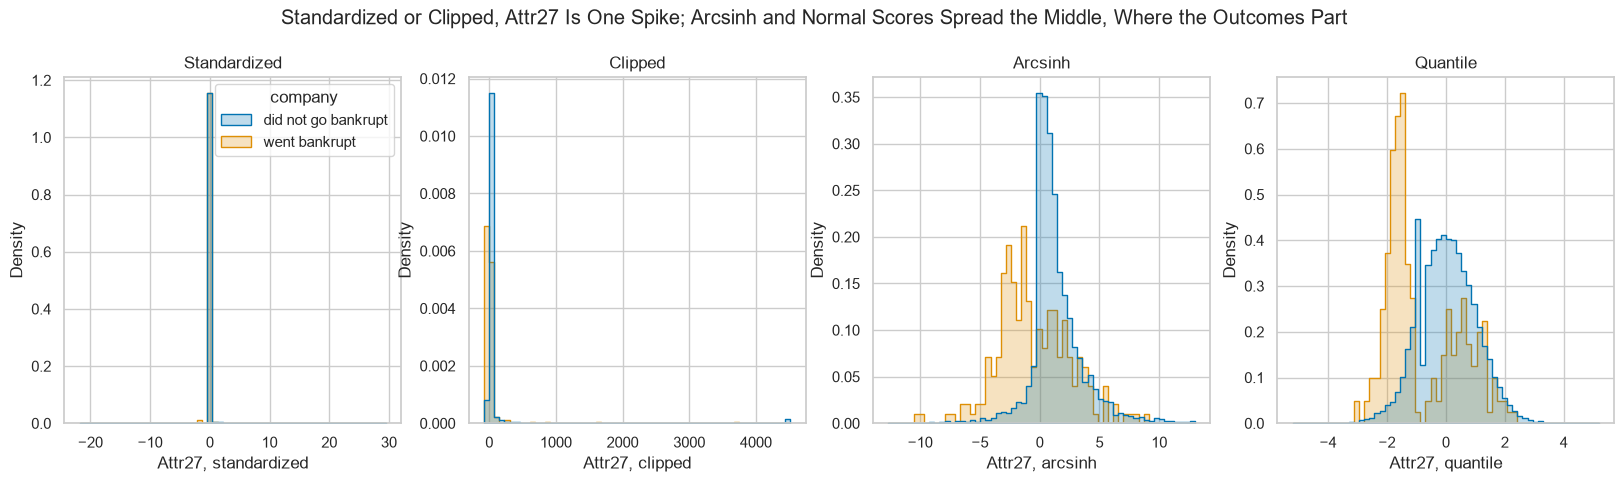

In [31]:
# the dropdown's four versions side by side, drawn as a still picture (dropdowns do not run on GitHub)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, version in zip(axes, versions.columns):
    draw_version(version, ax, legend=(version == "standardized"))
fig.suptitle("Standardized or Clipped, Attr27 Is One Spike; Arcsinh and Normal Scores Spread the Middle, Where the Outcomes Part", y=1.03)
plt.show()

Standardized, 97.69 percent of the companies sit within 0.1 of zero and one sits 29.5 sd away: a line sees a spike.

Clipping at -77.66 and 4,516.71 cuts the extremes and leaves the spike.

Arcsinh and the quantile step spread the middle, where the two outcomes can be told apart.

**Predict 4**

Q. Course 4's logistic pipeline with `StandardScaler` in place of the quantile step, on all 64 ratios. Write down its fold average precision, against 0.6624.

## Scoring Each Transform

In [32]:
# the imputer with indicators, then some steps, then Course 4's logistic regression
def logistic_with(steps):
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True))] + steps
                    + [("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])

scores["logistic, standardized"] = fold_ap(logistic_with([("scale", StandardScaler())]))
scores["logistic, arcsinh"] = fold_ap(logistic_with([("arcsinh", FunctionTransformer(np.arcsinh)), ("scale", StandardScaler())]))
summary(["logistic, standardized", "logistic, arcsinh", "logistic"])

,1,2,3,4,5,mean,sd
"logistic, standardized",0.4180,0.6256,0.4613,0.5431,0.5907,0.5277,0.0778
"logistic, arcsinh",0.5230,0.6924,0.6077,0.6863,0.7323,0.6483,0.0746
logistic,0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780


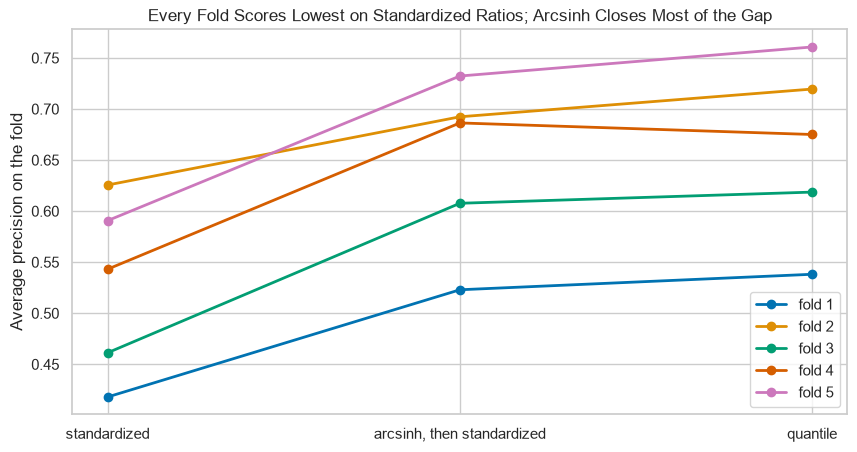

In [33]:
# one line per fold across the three ways, the quantile step last
order = ["logistic, standardized", "logistic, arcsinh", "logistic"]
for fold, row in scores[order].iterrows():
    plt.plot(["standardized", "arcsinh, then standardized", "quantile"], row.values, marker="o", linewidth=2, label="fold " + str(fold))
plt.ylabel("Average precision on the fold")
plt.title("Every Fold Scores Lowest on Standardized Ratios; Arcsinh Closes Most of the Gap")
plt.legend(loc="lower right")
plt.show()

Standardized: 0.5277, 0.1347 below the quantile step, and lower on every fold.

Arcsinh then standardized: 0.6483, within 0.02 of the quantile step, and above it on fold 4.

**For a line the shape of each column is worth 0.13 of average precision; the quantile step stays.**

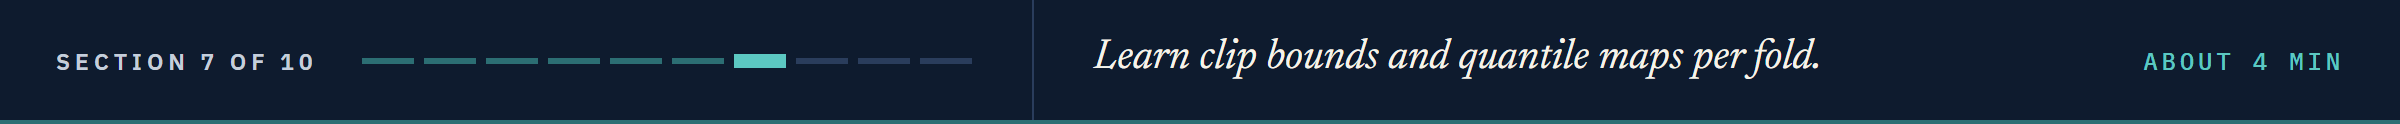

# Learned Inside the Fold

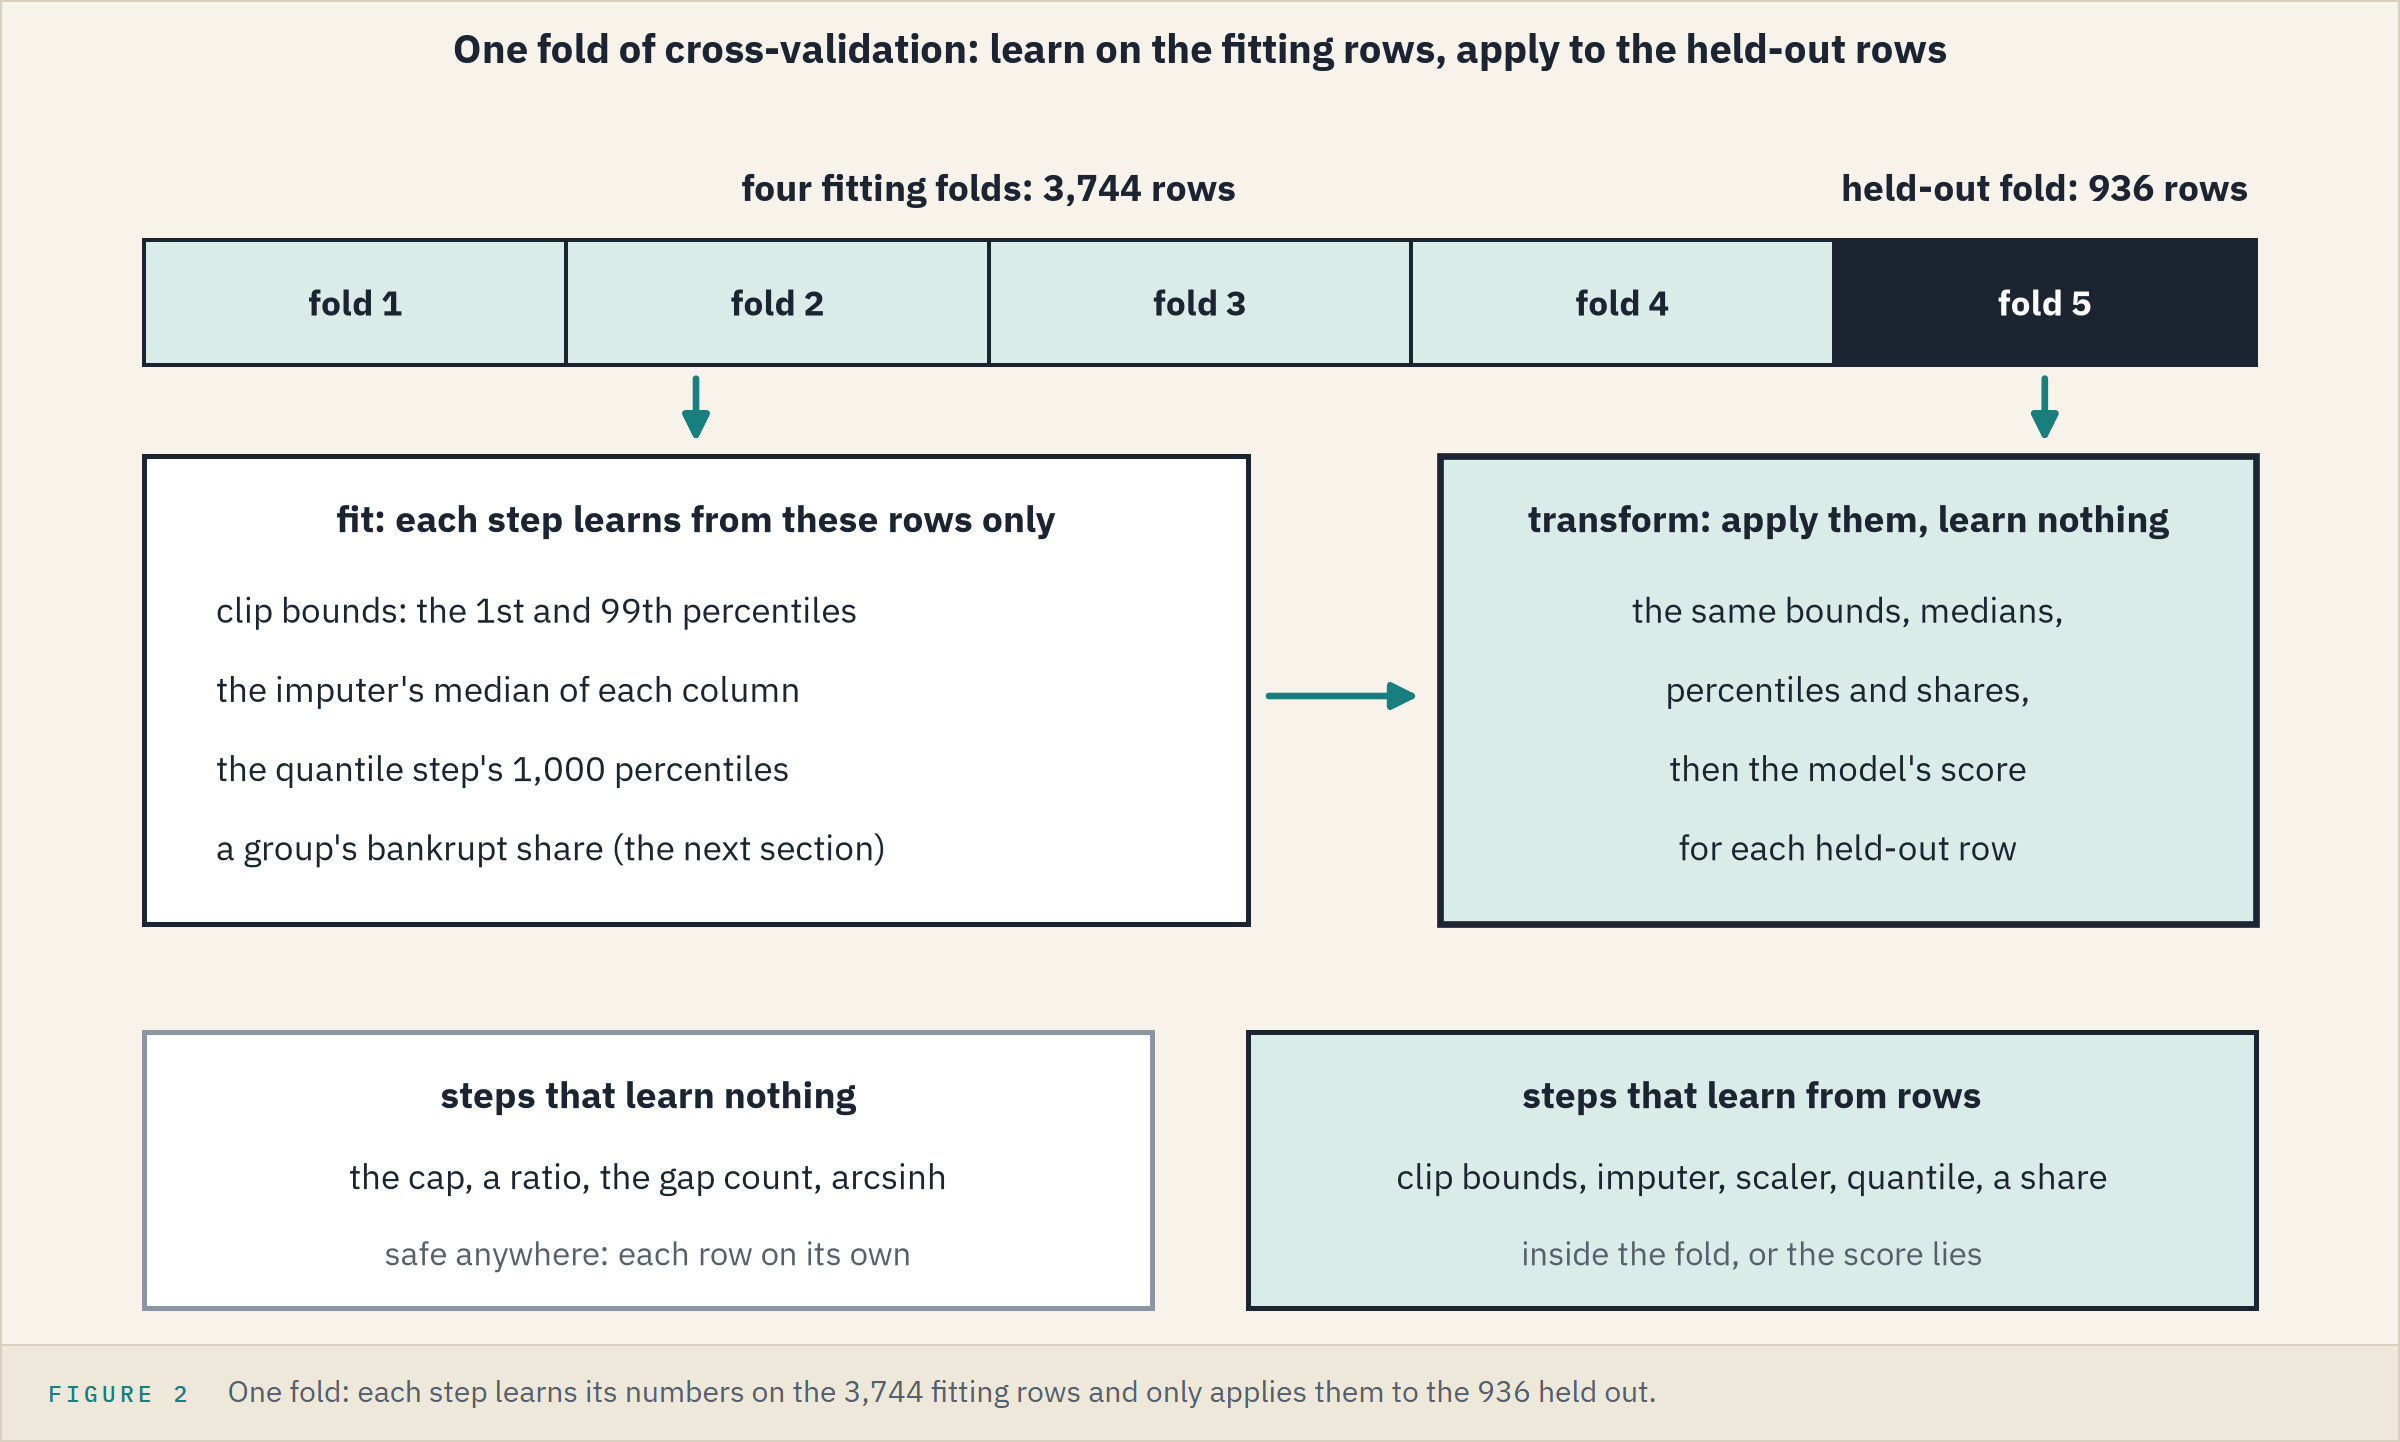

The clip bounds and the quantile map above were learned from all the training rows, so in cross-validation they would have seen every held-out fold.
A step that learns must learn on the fitting folds only, and only apply what it learned to the held-out fold.

## Five Folds, Five Sets of Clip Bounds

In [34]:
# each fold's clip bounds for Attr27, learned on its fitting rows, applied to its held-out rows
fold_bounds = []
for fit_rows, held_rows in folds.split(X_train, y_train):
    fit_values, held_values = coverage.iloc[fit_rows], coverage.iloc[held_rows]
    fold_low, fold_high = fit_values.quantile(0.01), fit_values.quantile(0.99)
    fold_bounds.append([fold_low, fold_high, ((held_values < fold_low) | (held_values > fold_high)).sum()])
fold_bounds = pd.DataFrame(fold_bounds, columns=["low", "high", "held-out rows clipped"], index=range(1, 6))
fold_bounds

,low,high,held-out rows clipped
1,-71.0499,5345.6420,18
2,-73.4695,4243.1570,21
3,-70.5788,5225.1740,19
4,-138.9016,3832.2680,14
5,-71.0727,4873.0280,19


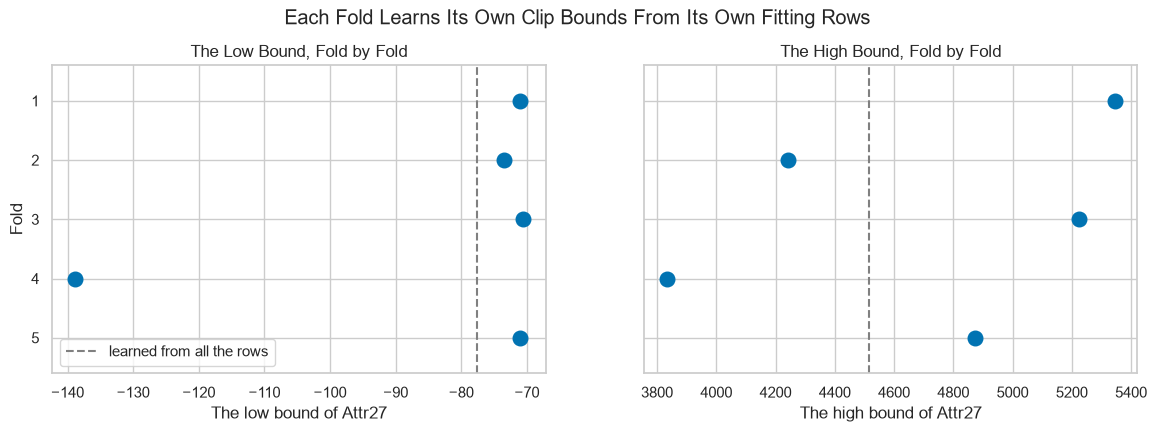

In [35]:
# each fold's low and high bound as dots, the bounds learned from all the rows dashed
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, side, everyone in zip(axes, ["low", "high"], [all_low, all_high]):
    ax.scatter(fold_bounds[side], fold_bounds.index, s=110, zorder=3)
    ax.axvline(everyone, color="gray", linestyle="--", label="learned from all the rows")
    ax.set(xlabel=f"The {side} bound of Attr27", title=f"The {side.capitalize()} Bound, Fold by Fold")
axes[0].set(yticks=range(1, 6), ylabel="Fold", ylim=(5.6, 0.4))
axes[0].legend(loc="lower left")
fig.suptitle("Each Fold Learns Its Own Clip Bounds From Its Own Fitting Rows", y=1.02)
plt.show()

The low bound sits between -70.58 and -73.47 in four folds and at -138.90 in fold 4; the high bound runs from 3,832 to 5,346.

Each fold's bounds clip 14 to 21 of its 936 held-out rows, rows that had no say in those bounds.

The bounds from all the rows, -77.66 and 4,516.71, had every held-out row's say.

## Five Quantile Maps

A fitted step keeps what it learned in attributes whose names end in `_`, as Course 4's `.statistics_` and `.coef_` do.
A quantile step keeps the value at each of its 1,000 stored percentiles in `.quantiles_`, one column per feature, and the percentiles in `.references_`.

In [36]:
# Course 4's logistic pipeline on the five folds again, each fold's fitted pipeline kept
fitted = cross_validate(logistic, X_train, y_train, cv=folds, scoring="average_precision", return_estimator=True, n_jobs=1)

# each fold's quantile map of Attr27: the value at every stored percentile
column = FEATURES.index("Attr27")
maps = pd.DataFrame({k: model["quantile"].quantiles_[:, column] for k, model in enumerate(fitted["estimator"], start=1)},
                    index=(fitted["estimator"][0]["quantile"].references_ * 100).round(2))
maps.iloc[[5, 500, 994]]

,1,2,3,4,5
0.5000,-383.8570,-330.0222,-321.3286,-447.2023,-286.6296
50.0500,1.0012,0.9667,0.9919,0.9669,0.9895
99.5000,15581.9389,13897.4605,16322.4114,12436.7588,15612.5596


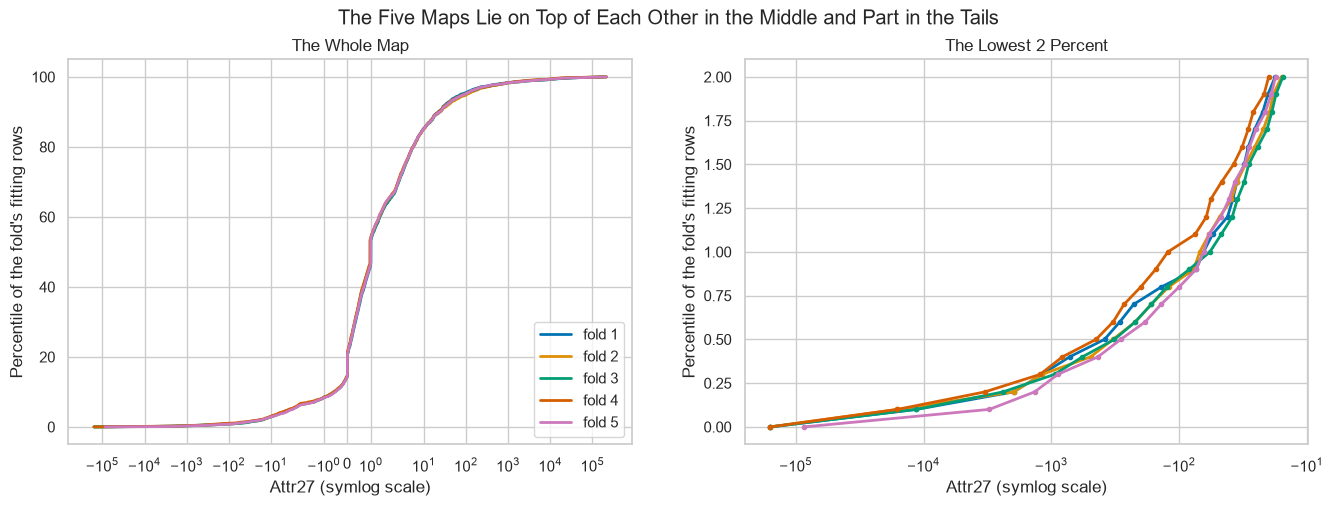

In [37]:
# the five maps on a symlog axis of Attr27, then the lowest 2 percent of each map up close
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for fold in maps:
    axes[0].plot(maps[fold], maps.index, linewidth=2, label="fold " + str(fold))
    axes[1].plot(maps[fold][maps.index <= 2], maps.index[maps.index <= 2], linewidth=2, marker="o", markersize=3)
axes[0].set(xscale="symlog", xlabel="Attr27 (symlog scale)", ylabel="Percentile of the fold's fitting rows", title="The Whole Map")
axes[1].set(xscale="symlog", xlabel="Attr27 (symlog scale)", ylabel="Percentile of the fold's fitting rows", title="The Lowest 2 Percent")
axes[0].legend(loc="lower right")
fig.suptitle("The Five Maps Lie on Top of Each Other in the Middle and Part in the Tails")
plt.show()

At the stored point nearest the median the five maps read 0.97 to 1.00.

At the 0.5th percentile they read -287 to -447, and at the 99.5th, 12,437 to 16,322.

**Each fold learns its own numbers from its own fitting rows; the held-out rows never vote. Inside a pipeline, cross-validation does this for every step.**

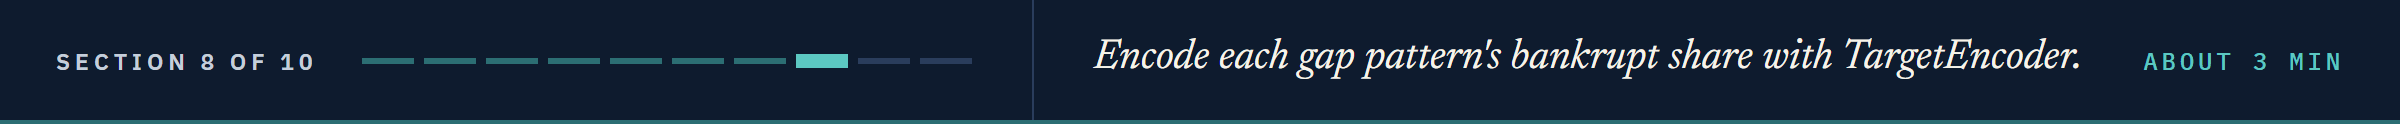

# A Feature Built From the Outcome

## The Bankrupt Share of Each Gap Pattern

A company's **gap pattern** marks which of the 64 ratios are missing on its row.

In [38]:
# each company's pattern as text: one character per ratio, 1 where it is missing; "".join glues a row's characters
pattern = X_train.isna().astype(int).astype(str).agg("".join, axis=1)
groups = y_train.groupby(pattern).agg(["size", "mean"])
small = groups[groups["size"] <= 3]
print("Patterns:", len(groups), " Held by one company:", (groups["size"] == 1).sum(),
      " Of 3 or fewer with a share of exactly 0 or 1:", small["mean"].isin([0, 1]).sum(), "of", len(small))

Patterns: 78  Held by one company: 33  Of 3 or fewer with a share of exactly 0 or 1: 50 of 52


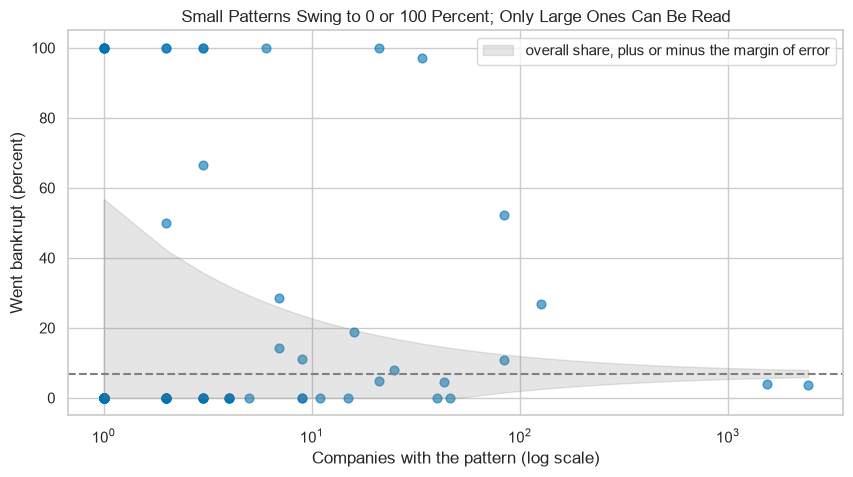

In [39]:
# each pattern's bankrupt share against its companies, and Course 1's margin of error around the overall share
share = y_train.mean()
sizes = np.arange(1, groups["size"].max() + 1)
margin = 1.96 * np.sqrt(share * (1 - share) / sizes)
plt.scatter(groups["size"], groups["mean"] * 100, s=40, alpha=0.6)
plt.fill_between(sizes, np.maximum(share - margin, 0) * 100, (share + margin) * 100, color="gray", alpha=0.2,
                 label="overall share, plus or minus the margin of error")
plt.axhline(share * 100, color="gray", linestyle="--")
plt.xscale("log")
plt.xlabel("Companies with the pattern (log scale)")
plt.ylabel("Went bankrupt (percent)")
plt.title("Small Patterns Swing to 0 or 100 Percent; Only Large Ones Can Be Read")
plt.legend(loc="upper right")
plt.show()

The funnel narrows as patterns grow: a share from a handful of companies swings far by chance.

50 of the 52 patterns of 3 companies or fewer show exactly 0 or 100 percent.

Two patterns of more than 20 companies sit near 100 percent, far outside the funnel.

## TargetEncoder Inside the Pipeline

**Target encoding** replaces each group with its outcome share.
`TargetEncoder(target_type="binary", cv=...)` learns the shares at `fit` from the rows it is given, and pulls a small group's share toward the overall share.
Inside its own fit it gives each fitting row a share learned without that row, on folds of its own: pass it a seeded splitter.

In [40]:
# the pattern as one more text column, a step that learns nothing
def add_pattern(frame):
    return frame.assign(pattern=frame.isna().astype(int).astype(str).agg("".join, axis=1))

# the pattern's bankrupt share, then the 64 ratios as each model takes them, then the model
def with_share(ratios, model):
    encoder = TargetEncoder(target_type="binary", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
    columns = ColumnTransformer([("share", encoder, ["pattern"]), ("ratios", ratios, FEATURES)])
    return Pipeline([("pattern", FunctionTransformer(add_pattern)), ("columns", columns), ("model", model)])

In [41]:
# LightGBM takes the ratios as they are; the logistic regression takes Course 4's imputer and quantile step first
course4_steps = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED))])
scores["LightGBM, pattern share"] = fold_ap(with_share("passthrough", booster))
scores["logistic, pattern share"] = fold_ap(with_share(course4_steps, logistic["logit"]))
summary(["LightGBM", "LightGBM, pattern share", "logistic", "logistic, pattern share"])

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
"LightGBM, pattern share",0.7193,0.8096,0.7382,0.7893,0.8092,0.7731,0.0374
logistic,0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780
"logistic, pattern share",0.5441,0.7263,0.6194,0.6812,0.7578,0.6657,0.0766


`"passthrough"` sends the ratios through unchanged, and `logistic["logit"]` is the pipeline's own logistic regression step.

The share moves LightGBM to 0.7731 and the logistic pipeline to 0.6657, each far inside its fold sd.

The 64 ratios' own gaps already tell both models where the gaps are.

**A column built from the outcome is learned from each fold's fitting rows only, small groups shrunk; done so, it adds nothing here.**

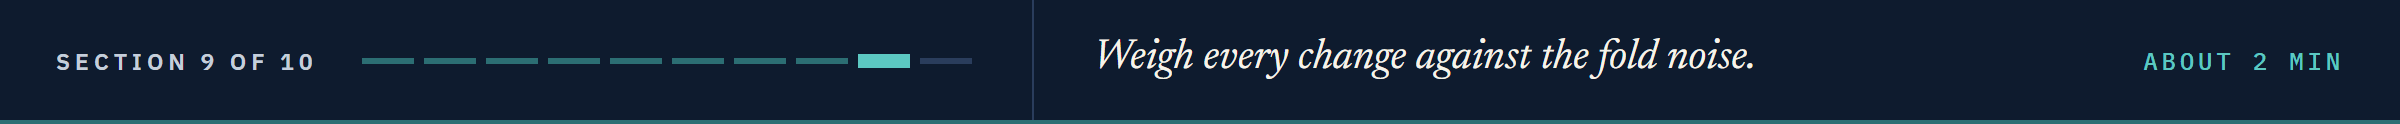

# Model Performance Comparison

**Predict 5**

Q. The three ratios, `ratio_step`, in front of LightGBM. Write down its fold average precision, against 0.7783.

## Three Ratios for Both Models

In [42]:
# the ratio step in front of each model
scores["LightGBM, ratios"] = fold_ap(Pipeline([("ratios", ratio_step), ("lightgbm", booster)]))
scores["logistic, ratios"] = fold_ap(Pipeline([("ratios", ratio_step), ("logistic", logistic)]))
summary(["LightGBM", "LightGBM, ratios", "logistic", "logistic, ratios"])

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
"LightGBM, ratios",0.7001,0.8086,0.7400,0.7901,0.8241,0.7726,0.0460
logistic,0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780
"logistic, ratios",0.5339,0.7161,0.6231,0.6732,0.7617,0.6616,0.0786


LightGBM with the ratios: 0.7726, a hair below its base; the logistic pipeline: 0.6616.

Ratios analysts trust add nothing measurable to either model on this file.

A tree may reach such a ratio with splits on its parts; nothing today tests that, so it stays a possibility.

## What Each Change Adds

In [43]:
# each change against its base model, fold by fold: the base is the name before the comma
changes = pd.DataFrame({name: scores[name] - scores[name.split(",")[0]] for name in scores if "," in name})
changes.mean().sort_values()

logistic, standardized    -0.1347
LightGBM, median fill     -0.0223
logistic, arcsinh         -0.0141
LightGBM, gap count       -0.0068
LightGBM, ratios          -0.0058
LightGBM, pattern share   -0.0052
logistic, ratios          -0.0008
logistic, gap count        0.0010
logistic, pattern share    0.0033
dtype: float64

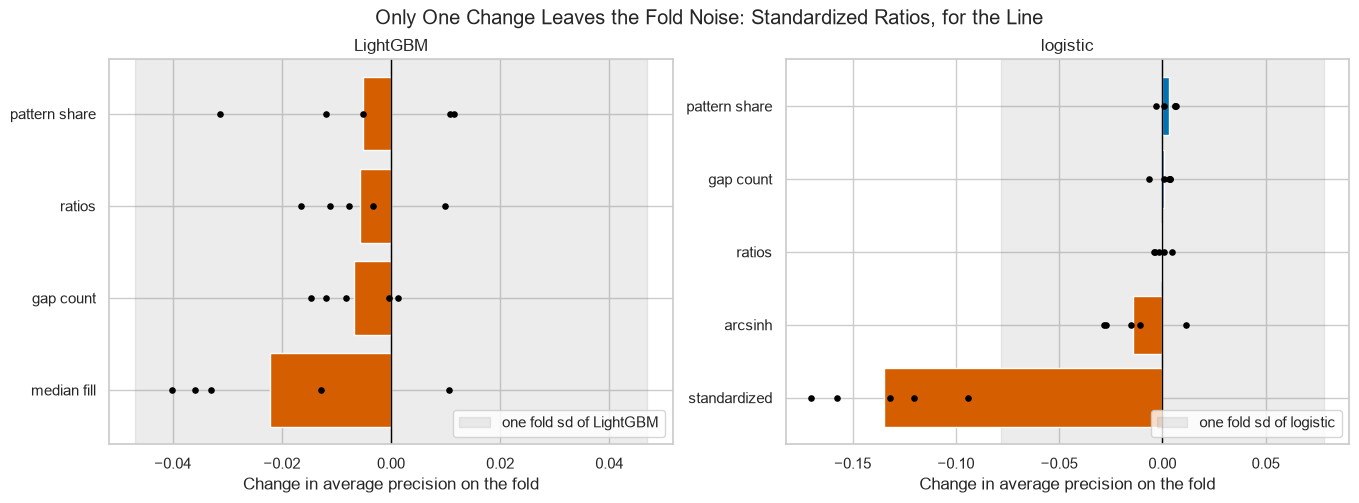

In [44]:
# a tornado per base model: each change's mean as a bar, its folds as dots, the base model's fold sd shaded
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, base in zip(axes, ["LightGBM", "logistic"]):
    names = [name for name in changes.mean().sort_values().index if name.startswith(base + ",")]
    labels = [name.split(", ")[1] for name in names]
    sd = scores[base].std(ddof=0)
    ax.axvspan(-sd, sd, color="gray", alpha=0.15, label="one fold sd of " + base)
    ax.barh(labels, changes[names].mean(), color=["C3" if change < 0 else "C0" for change in changes[names].mean()])
    for label, name in zip(labels, names):
        ax.scatter(changes[name], [label] * 5, color="black", s=14, zorder=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(xlabel="Change in average precision on the fold", title=base)
    ax.legend(loc="lower right")
fig.suptitle("Only One Change Leaves the Fold Noise: Standardized Ratios, for the Line")
plt.show()

Every LightGBM change is a small loss, the largest the median fill's 0.0223, all inside its fold sd.

For the logistic pipeline only standardized ratios fall outside the band.

**On this file no new column lifts either model beyond the fold noise; what moved the line was the shape of its columns.**

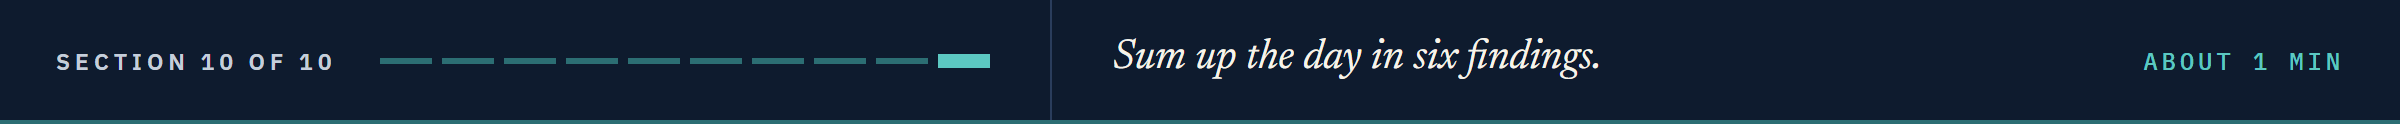

# Insights and Conclusion

The recipe's cap, written into a column, took the line from 42.31 to 40.87 bp, level with boosting.

A ratio whose denominator crosses zero reads backwards: the 269 companies with negative debt to equity were 29.0 percent bankrupt.

LightGBM's own handling of gaps beats a median fill by 0.022, and gap counts, ratios and pattern shares add nothing beyond the folds' noise.

For the logistic pipeline the transform is worth 0.13 of average precision.

Every step that learns from rows (clip bounds, medians, percentiles, shares) learns inside the fold.

What a model leans on here is an association in this file, nothing more.

**Day 13 keeps both models and rebalances the rows instead of the columns.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Write a known shape into a column with a cap and score it on folds.
* Build a ratio from two ratios and guard its division with `.replace()`.
* Put a function in a pipeline with `FunctionTransformer`.
* Count gaps, and compare a median fill with LightGBM's own handling of gaps.
* Transform a long-tailed ratio for a linear model, and read what each fold's step learned.
* Encode a group's outcome share with `TargetEncoder` inside the folds.
* Weigh a new column's gain against the fold noise.

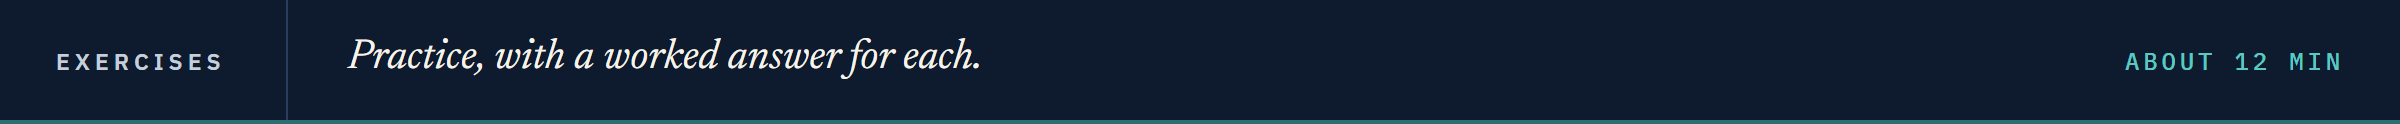

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Flag for Negative Equity**

Q. Write `add_negative_equity(frame)`, which adds a column `negative_equity`, 1 where `Attr10` is below 0 and 0 elsewhere. Put it in a `FunctionTransformer` in front of `logistic` and in front of `booster`, and store their fold average precision in `ex1_logistic` and `ex1_lightgbm`.

In [46]:
# your code here
ex1_logistic = ...
ex1_lightgbm = ...

In [47]:
check("Exercise 1 the logistic pipeline with the flag", ex1_logistic, 0.6617413278376896)
check("Exercise 1 LightGBM with the flag", ex1_lightgbm, 0.7783289352753582)

Exercise 1 the logistic pipeline with the flag: not attempted yet
Exercise 1 LightGBM with the flag: not attempted yet


### Exercise 2

**The Imputer's Median in Each Fold**

Q. From `fitted`, read the median imputer's learned value for `Attr37` in each fold's pipeline (`.statistics_`, one per feature). Store the five values, rounded to 4 decimals, in a list `ex2_medians`.

In [48]:
# your code here
ex2_medians = ...

In [49]:
check("Exercise 2 the five medians of Attr37", ex2_medians, [3.5918, 3.6901, 3.5256, 3.558, 3.5455])

Exercise 2 the five medians of Attr37: not attempted yet


### Exercise 3

**Arcsinh Before the Quantile Step**

Q. Put `FunctionTransformer(np.arcsinh)` in front of Course 4's quantile step with `logistic_with`, and store its fold average precision in `ex3_ap`. Then say in one line why it lands where it does.

In [50]:
# your code here
ex3_ap = ...

In [51]:
check("Exercise 3 arcsinh before the quantile step", ex3_ap, 0.6617384466998932)

Exercise 3 arcsinh before the quantile step: not attempted yet


### Exercise 4: AI check

**The Pattern Share That Saw Every Row**

You asked an AI assistant for a column holding each gap pattern's bankrupt share, scored on the folds.
This came back.
It runs, and it lifts the logistic pipeline above 0.6624.
Test it, then find the one bug.

In [52]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def add_pattern_share(frame, target):
    # each company's gap pattern, and the bankrupt share of the companies with the same pattern
    pattern = frame.isna().astype(int).astype(str).agg("".join, axis=1)
    return frame.assign(pattern_share=pattern.map(target.groupby(pattern).mean()))

X_shared = add_pattern_share(X_train, y_train)
ai_scores = cross_val_score(logistic, X_shared, y_train, cv=folds, scoring="average_precision", n_jobs=1)
print("Fold average precision with the pattern share:", round(ai_scores.mean(), 4))

Fold average precision with the pattern share: 0.68


In [53]:
# the test: a held-out company's share must come from its fold's fitting rows only
for fit_rows, held_rows in folds.split(X_train, y_train):
    fold_shares = y_train.iloc[fit_rows].groupby(pattern.iloc[fit_rows]).mean()
    expected = pattern.iloc[held_rows].map(fold_shares).fillna(y_train.iloc[fit_rows].mean())
    assert np.allclose(X_shared["pattern_share"].iloc[held_rows], expected), "a held-out share was learned from rows that include the held-out companies"

AssertionError: a held-out share was learned from rows that include the held-out companies

Q. Fix it: inside the fold loop learn the shares from the fitting rows, give a pattern the fold has not seen the fitting rows' overall share, fit `logistic` on the fitting rows and score the held-out rows with `average_precision_score`. Store the mean of the five fold scores in `ex4_ap`.

In [54]:
# your code here
ex4_ap = ...

In [55]:
check("Exercise 4 the pattern share learned inside the folds", ex4_ap, 0.6507706682796042)

Exercise 4 the pattern share learned inside the folds: not attempted yet


## Congratulations!

You wrote a generator's bend into one column and watched a plain least squares line catch boosting.
On real statements you built ratios from ratios and found where one breaks, filled gaps two ways, and saw a linear model's score move more with the shape of its columns than with any new column.
You learned every number a column needs inside the fold, and caught a share that had seen its own answer.
In Day 13 you keep both models and rebalance the rows instead of the columns.

[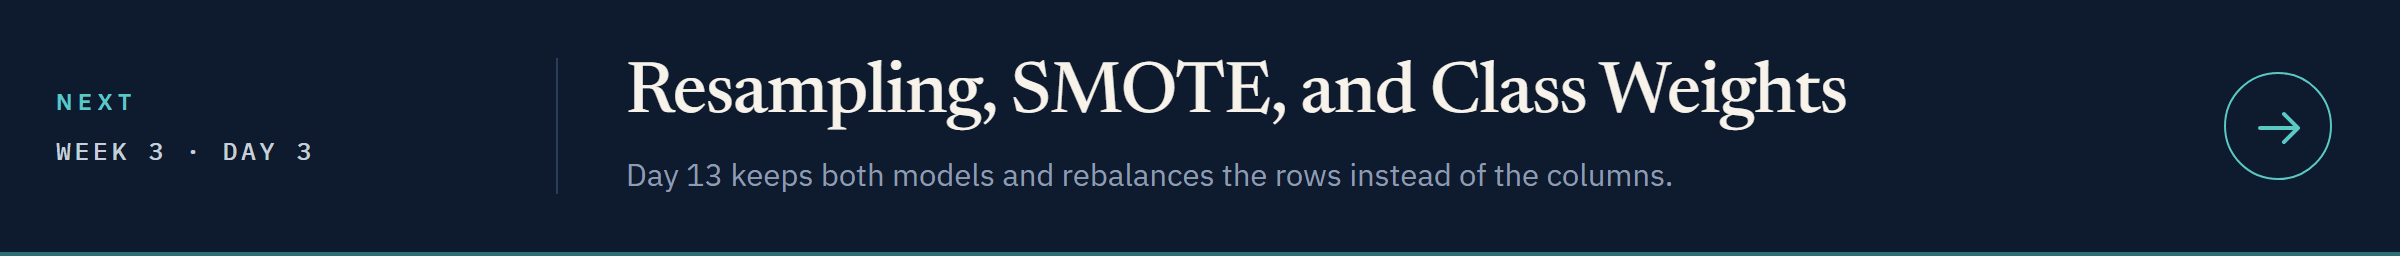](../day3/13_resampling_smote_and_class_weights.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day3/13_resampling_smote_and_class_weights.ipynb)